# VIPEEGNet — local reproduction (Ubuntu / single GPU)

Faithful reproduction of Sunyuri's VIPEEGNet (https://www.kaggle.com/code/sunyuri/hms-vipeegnet,
arXiv 2507.08874). **The training recipe is unchanged** (data, augmentation, model, LR schedule,
two-stage training, seed). What changed versus the previous `/workspace` notebook:

| # | Change | Affects results? |
|---|--------|------------------|
| 1 | Paths come from one `PROJECT_DIR` parameter instead of hard-coded `/workspace/...` | No |
| 2 | `pip install` cell removed — environment is set up once with `setup.sh` (GPU-enabled TF 2.19) | No |
| 3 | `FOLD_MODE`: `'groupkfold'` (original paper split) or `'csv'` (shared `patient_folds.csv`). See note below | **Yes — choose deliberately** |
| 4 | Segment lookup precomputed once (`FAST_LOOKUP`) instead of scanning all 106,800 rows of `train.csv` for every sample. Same rows, same order, same RNG calls — verified identical | No (faster) |
| 5 | EEG caching runs in parallel and writes files atomically | No (faster, crash-safe) |
| 6 | GPU check, smoke-test mode, optional fold resume, papermill `parameters` cell | No |
| 7 | Evaluation reports both pooled OOF KLD and mean-of-folds KLD (the paper's 0.225 is mean-of-folds) | No |
| 8 | Final cell packages the 5 stage-2 weight files for the Kaggle inference notebook | No |

**About the folds.** The previous notebook said `patient_folds.csv` was identical to GroupKFold,
but its fold sizes (exactly 390 patients per fold, validation sizes 3,702–4,421) are not what
`GroupKFold` produces — GroupKFold balances *sample* counts (~4,037 each), not patient counts.
So that run used a different split from the paper. `'groupkfold'` reproduces the original;
it also writes `patient_folds_groupkfold.csv` so TCS-Net / EfficientNetB0 can use the identical split.

**Expected:** HQ OOF KLD ≈ 0.218–0.225 (±0.003 run-to-run from mixed-precision GPU nondeterminism).

## Parameters (papermill can override: `-p SMOKE_TEST True`)

In [1]:
PROJECT_DIR = '~/hms'              # data must be in PROJECT_DIR/hms-data (train.csv, train_eegs/)
FOLD_MODE = 'groupkfold'           # 'groupkfold' = original paper split | 'csv' = PROJECT_DIR/fair_comparison/patient_folds.csv
FOLDS_TO_RUN = [0, 1, 2, 3, 4]
SKIP_COMPLETED_FOLDS = False       # True = skip folds whose stage-2 weights already exist (resume after a crash)
SMOKE_TEST = False                 # True = ~250 patients, 3+1 epochs, fold 0 only — a 10–15 min pipeline check
FAST_LOOKUP = True                 # False = original per-sample pandas scan (identical output, much slower)
N_CACHE_WORKERS = 8                # parallel workers for the one-time EEG preprocessing
SEED = 2024                        # 2024 = the original. Any other seed writes to separate *_seed<SEED> folders

In [2]:
# Parameters
PROJECT_DIR = "/home/nfs/jhb-dehzangi/ws04/gs1147/hms"
SEED = 2026


In [3]:
import os, gc, time, json, warnings
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import signal as sp_signal
from sklearn.model_selection import GroupKFold
from sklearn.metrics import confusion_matrix, roc_auc_score
from tqdm.auto import tqdm
from joblib import Parallel, delayed

import tensorflow as tf
gpus = tf.config.list_physical_devices('GPU')
print(f'TF {tf.__version__} | GPUs: {gpus}')
assert gpus, ('TensorFlow cannot see the GPU. Check `nvidia-smi`, and that this kernel is the '
              'hms-vipeegnet venv where tensorflow[and-cuda]==2.19.0 is installed.')

for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

# Reproducibility — original uses SEED=2024 (set in the parameters cell)
np.random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['TF_DETERMINISTIC_OPS'] = '1'
tf.random.set_seed(SEED)
tf.keras.utils.set_random_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()
except Exception:
    pass

# Mixed precision — original enables this
policy = tf.keras.mixed_precision.Policy('mixed_float16')
tf.keras.mixed_precision.set_global_policy(policy)
print(f'Mixed precision: {policy.name}')

E0000 00:00:1792939099.820429  514080 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1792939099.827974  514080 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1792939099.845137  514080 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792939099.845157  514080 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792939099.845159  514080 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking the same target more than once.
W0000 00:00:1792939099.845160  514080 computation_placer.cc:177] computation placer already registered. Please check linka

TF 2.19.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mixed precision: mixed_float16


In [4]:
# === Configuration (recipe values identical to original) ===
PROJECT_DIR = os.path.abspath(os.path.expanduser(PROJECT_DIR))
BASE_DIR   = f'{PROJECT_DIR}/hms-data'
RUN_SUFFIX = '' if SEED == 2024 else f'_seed{SEED}'   # a second seed never overwrites the original run
OUTPUT_DIR = f'{PROJECT_DIR}/vipeegnet/output' + RUN_SUFFIX + ('_smoke' if SMOKE_TEST else '')
CACHE_DIR  = f'{PROJECT_DIR}/eeg_cache_v2'
FAIR_DIR   = f'{PROJECT_DIR}/fair_comparison'
for d in (OUTPUT_DIR, CACHE_DIR, FAIR_DIR):
    os.makedirs(d, exist_ok=True)
assert os.path.isfile(f'{BASE_DIR}/train.csv'), f'{BASE_DIR}/train.csv not found — run download_data.sh first'

SFREQ = 200; RSFREQ = 200
EEG_LENGTH = 50; EEG_LENGTH_USED = 50
EEG_CHANNEL_USED = 16
filter_range = [0.5, 45]
BATCHSIZE = 16
LEARN_RATE = 1e-3
EPOCHS = 3 if SMOKE_TEST else 15
SPLITS = 5
if SMOKE_TEST:
    FOLDS_TO_RUN = [0]

BRAIN = [
    'Fp1-F7', 'F7-T3', 'T3-T5', 'T5-O1',     # Left temporal
    'Fp1-F3', 'F3-C3', 'C3-P3', 'P3-O1',     # Left parasagittal
    'Fz-Cz', 'Cz-Pz',                         # Central (dropped later)
    'Fp2-F4', 'F4-C4', 'C4-P4', 'P4-O2',     # Right parasagittal
    'Fp2-F8', 'F8-T4', 'T4-T6', 'T6-O2',     # Right temporal
]
TARGET_COLS = ['seizure_vote', 'lpd_vote', 'gpd_vote', 'lrda_vote', 'grda_vote', 'other_vote']
CLASS_NAMES = ['Seizure', 'LPD', 'GPD', 'LRDA', 'GRDA', 'Other']
print(f'PROJECT_DIR={PROJECT_DIR}\nOUTPUT_DIR={OUTPUT_DIR}\nFOLD_MODE={FOLD_MODE} | folds={FOLDS_TO_RUN} | '
      f'EPOCHS={EPOCHS} | SMOKE_TEST={SMOKE_TEST}')

PROJECT_DIR=/home/nfs/jhb-dehzangi/ws04/gs1147/hms
OUTPUT_DIR=/home/nfs/jhb-dehzangi/ws04/gs1147/hms/vipeegnet/output_seed2026
FOLD_MODE=groupkfold | folds=[0, 1, 2, 3, 4] | EPOCHS=15 | SMOKE_TEST=False


## Data loading — deduplication (matches original)

In [5]:
df_full = pd.read_csv(os.path.join(BASE_DIR, 'train.csv'))
print(f'Full df: {len(df_full):,} rows')

# Original: deduplicate on (eeg_id + all vote columns) -> 20,183 records over 17,089 EEGs
train = df_full.drop_duplicates(['eeg_id'] + TARGET_COLS).reset_index(drop=True)
print(f'Deduplicated: {len(train):,} unique records')

TARGETS_RAW = [c + '_raw' for c in TARGET_COLS]
train[TARGETS_RAW] = train[TARGET_COLS].values

y_data = train[TARGET_COLS].values.astype(np.float32)
y_data = y_data / y_data.sum(axis=1, keepdims=True)
train[TARGET_COLS] = y_data
train['total_votes_raw'] = train[TARGETS_RAW].sum(axis=1)
print(f'Vote range: {train["total_votes_raw"].min()} - {train["total_votes_raw"].max()}')

if SMOKE_TEST:
    keep = pd.Series(train['patient_id'].unique()).sample(250, random_state=0)
    train = train[train['patient_id'].isin(keep)].reset_index(drop=True)
    print(f'SMOKE_TEST: using {len(train):,} records from 250 patients')

Full df: 106,800 rows
Deduplicated: 20,183 unique records
Vote range: 1 - 28


## EEG preprocessing and caching

In [6]:
# Butterworth filter — original: clip FIRST, then filter
b, a = sp_signal.butter(3, np.float32(filter_range) * 2 / RSFREQ, 'bandpass')

def preprocess_eeg_recording(eeg_id, eeg_dir):
    """18-channel bipolar montage -> clip [-1024, 1024] -> filtfilt 0.5–45 Hz. Returns (18, T) float32."""
    eeg_default = pd.read_parquet(os.path.join(eeg_dir, f'{eeg_id}.parquet'))
    eeg_channels = []
    for channel in BRAIN:
        ch1, ch2 = channel.split('-')
        if ch1 in eeg_default.columns and ch2 in eeg_default.columns:
            ch_data = (eeg_default[ch1].values - eeg_default[ch2].values)
        else:
            ch_data = np.zeros(len(eeg_default))
        ch_data[np.isnan(ch_data)] = 0
        eeg_channels.append(ch_data.reshape(1, -1))
    eeg = np.concatenate(eeg_channels, axis=0)
    eeg = np.clip(eeg, -1024, 1024)
    eeg = sp_signal.filtfilt(b, a, eeg, axis=1)
    return np.array(eeg, dtype=np.float32)

def cache_one(eid, eeg_dir, cache_dir):
    cp = os.path.join(cache_dir, f'{eid}.npy')
    if os.path.exists(cp):
        return
    tmp = cp + '.tmp'
    with open(tmp, 'wb') as f:          # atomic write: an interrupted run never leaves a half file
        np.save(f, preprocess_eeg_recording(eid, eeg_dir))
    os.replace(tmp, cp)

print('Preprocessing functions defined.')

Preprocessing functions defined.


In [7]:
PATH = os.path.join(BASE_DIR, 'train_eegs')
unique_ids = train['eeg_id'].unique()
todo = [e for e in unique_ids if not os.path.exists(os.path.join(CACHE_DIR, f'{e}.npy'))]
print(f'EEG IDs: {len(unique_ids):,} | Cached: {len(unique_ids)-len(todo):,} | Remaining: {len(todo):,}')

if todo:
    t0 = time.time()
    Parallel(n_jobs=N_CACHE_WORKERS, batch_size=16)(
        delayed(cache_one)(e, PATH, CACHE_DIR) for e in tqdm(todo, desc='Caching'))
    print(f'Cached in {(time.time()-t0)/60:.1f} min')

eegs = {}
for eid in tqdm(unique_ids, desc='Loading'):
    eegs[eid] = np.load(os.path.join(CACHE_DIR, f'{eid}.npy'))
print(f'Loaded {len(eegs):,} recordings ({sum(v.nbytes for v in eegs.values())/1e9:.1f} GB in RAM).')

EEG IDs: 17,089 | Cached: 17,089 | Remaining: 0


Loading:   0%|          | 0/17089 [00:00<?, ?it/s]

Loading:   0%|          | 54/17089 [00:00<00:31, 537.88it/s]

Loading:   1%|          | 108/17089 [00:00<00:39, 428.61it/s]

Loading:   1%|          | 153/17089 [00:00<00:40, 421.02it/s]

Loading:   1%|          | 196/17089 [00:00<00:40, 414.93it/s]

... (380 outputs left out)

Loading: 100%|█████████▉| 17044/17089 [00:40<00:00, 438.26it/s]

Loading: 100%|█████████▉| 17088/17089 [00:40<00:00, 427.21it/s]

Loading: 100%|██████████| 17089/17089 [00:40<00:00, 424.69it/s]

Loaded 17,089 recordings (19.7 GB in RAM).


## Fold split

In [8]:
pf_path = f'{FAIR_DIR}/patient_folds.csv'

if FOLD_MODE == 'csv':
    assert os.path.isfile(pf_path), f'{pf_path} not found'
    pf = pd.read_csv(pf_path)[['patient_id', 'fold']]
    train = train.merge(pf, on='patient_id', how='left')
    assert train['fold'].notna().all(), 'some rows have no fold — patient_id missing from splits CSV'
    train['fold'] = train['fold'].astype(int)
    fold_source = 'patient_folds.csv'
elif FOLD_MODE == 'groupkfold':
    # Exactly the original: GroupKFold(5) on the deduplicated df, grouped by patient_id
    train['fold'] = -1
    gkf = GroupKFold(n_splits=SPLITS)
    for k, (_, v) in enumerate(gkf.split(train, train[TARGET_COLS[0]], train['patient_id'])):
        train.loc[v, 'fold'] = k
    mapping = train[['patient_id', 'fold']].drop_duplicates()
    assert mapping['patient_id'].is_unique, 'a patient landed in two folds'
    if not SMOKE_TEST:
        out = f'{FAIR_DIR}/patient_folds_groupkfold.csv'
        mapping.sort_values('patient_id').to_csv(out, index=False)
        print(f'Saved patient->fold mapping for other models: {out}')
    fold_source = 'GroupKFold(5) on dedup df'
else:
    raise ValueError(FOLD_MODE)

folds = []
for k in range(SPLITS):
    val_idx = train.index[train['fold'] == k].to_numpy()
    train_idx = train.index[train['fold'] != k].to_numpy()
    folds.append((train_idx, val_idx))
    tr, vl = train.iloc[train_idx], train.iloc[val_idx]
    print(f'Fold {k}: Tr {len(tr):,} ({tr["patient_id"].nunique()} pat) | '
          f'Val {len(vl):,} ({vl["patient_id"].nunique()} pat) | '
          f'HQ tr {(tr["total_votes_raw"]>=10).sum():,} val {(vl["total_votes_raw"]>=10).sum():,}')

Saved patient->fold mapping for other models: /home/nfs/jhb-dehzangi/ws04/gs1147/hms/fair_comparison/patient_folds_groupkfold.csv
Fold 0: Tr 16,146 (1561 pat) | Val 4,037 (389 pat) | HQ tr 4,974 val 1,376
Fold 1: Tr 16,146 (1560 pat) | Val 4,037 (390 pat) | HQ tr 5,122 val 1,228
Fold 2: Tr 16,146 (1559 pat) | Val 4,037 (391 pat) | HQ tr 5,121 val 1,229
Fold 3: Tr 16,147 (1560 pat) | Val 4,036 (390 pat) | HQ tr 5,195 val 1,155
Fold 4: Tr 16,147 (1560 pat) | Val 4,036 (390 pat) | HQ tr 4,988 val 1,362


## Data generator — original logic

`FAST_LOOKUP` builds, once, a dict `(eeg_id, 6 raw votes) -> (eeg_sub_id[], offset[])` in the
original `train.csv` row order. The generator then makes the same `np.random` calls in the same
order as the original pandas scan, so the batches are bit-identical; it is just ~100× cheaper per sample.

In [9]:
SEG_LOOKUP = {}
if FAST_LOOKUP:
    _cols = ['eeg_id'] + TARGET_COLS
    for key, g in df_full[_cols + ['eeg_sub_id', 'eeg_label_offset_seconds']].groupby(_cols, sort=False):
        SEG_LOOKUP[tuple(int(k) for k in key)] = (g['eeg_sub_id'].to_numpy(),
                                                  g['eeg_label_offset_seconds'].to_numpy())
    print(f'Segment lookup: {len(SEG_LOOKUP):,} keys')


class DataGenerator(tf.keras.utils.Sequence):
    def __init__(self, dataframe, batch_size=16, shuffle=False,
                 sample_weights=False, mode='train', eegs=None, stage=2, **kwargs):
        super().__init__(**kwargs)
        self.dataframe = dataframe
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.sample_weights = sample_weights
        self.mode = mode
        self.eegs = eegs
        self.stage = stage
        self._eid = dataframe['eeg_id'].to_numpy()
        self._raw = dataframe[TARGETS_RAW].to_numpy().astype(np.int64) if mode != 'test' else None
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.dataframe) / self.batch_size))

    def __getitem__(self, index):
        indexes = self.indexes[index * self.batch_size:(index + 1) * self.batch_size]
        return self._data_generation(indexes)

    def on_epoch_end(self):
        self.indexes = np.arange(len(self.dataframe))
        if self.shuffle:
            np.random.shuffle(self.indexes)

    # ---- returns (eeg_id, start_seconds, target, sample_weight) ----
    def _resolve_fast(self, i):
        eid = int(self._eid[i])
        if self.mode == 'test':
            return eid, 0, None, None
        raw = self._raw[i]
        sw = raw.sum() / 20
        sub_ids, offs = SEG_LOOKUP[(eid,) + tuple(int(v) for v in raw)]
        if self.mode == 'train':
            k = np.random.permutation(len(offs))[0]
        else:  # valid: middle segment by eeg_sub_id
            k = np.argsort(sub_ids, kind='stable')[len(offs) // 2]
        r_eeg = offs[k]
        if self.mode == 'train':
            r_eeg = r_eeg + np.random.random() * 10 - 5
            r_eeg = max(0, r_eeg)
            r_eeg = min(r_eeg, self.eegs[eid].shape[1] / RSFREQ - 50)
        return eid, r_eeg, raw / raw.sum(), sw

    def _resolve_legacy(self, i):  # original code path, verbatim logic
        row = self.dataframe.iloc[i]
        sw = None
        if self.mode != 'test':
            sw = sum(row[TARGETS_RAW].values) / 20
        if self.mode == 'test':
            return row['eeg_id'], 0, None, None
        mask = ((df_full['eeg_id'] == row['eeg_id']) &
                (df_full['seizure_vote'] == row['seizure_vote_raw']) &
                (df_full['lpd_vote'] == row['lpd_vote_raw']) &
                (df_full['gpd_vote'] == row['gpd_vote_raw']) &
                (df_full['lrda_vote'] == row['lrda_vote_raw']) &
                (df_full['grda_vote'] == row['grda_vote_raw']) &
                (df_full['other_vote'] == row['other_vote_raw']))
        rows = df_full.loc[mask].reset_index(drop=True)
        if self.mode == 'train':
            rows = rows.iloc[np.random.permutation(len(rows))].reset_index(drop=True)
            row = rows.loc[0]
        elif self.mode == 'valid':
            row = rows.sort_values(by='eeg_sub_id').reset_index(drop=True).iloc[len(rows) // 2]
        r_eeg = row['eeg_label_offset_seconds']
        if self.mode == 'train':
            r_eeg = r_eeg + np.random.random() * 10 - 5
            r_eeg = max(0, r_eeg)
            r_eeg = min(r_eeg, self.eegs[row['eeg_id']].shape[1] / RSFREQ - 50)
        tgt = row[TARGET_COLS].values / sum(row[TARGET_COLS].values)
        return row['eeg_id'], r_eeg, tgt, sw

    def _data_generation(self, indexes):
        x_eeg = np.zeros((len(indexes), EEG_CHANNEL_USED, round(EEG_LENGTH_USED * RSFREQ)), dtype='float32')
        y = np.zeros((len(indexes), len(TARGET_COLS)), dtype='float32')
        sample_w = np.zeros((len(indexes), 1), dtype='float32')
        resolve = self._resolve_fast if FAST_LOOKUP else self._resolve_legacy

        for j, i in enumerate(indexes):
            eid, r_eeg, tgt, sw = resolve(i)

            eeg = self.eegs[eid][:, round(r_eeg * RSFREQ):round((r_eeg + 50) * RSFREQ)]
            eeg = np.concatenate((eeg[0:EEG_CHANNEL_USED // 2, :],
                                  eeg[-EEG_CHANNEL_USED // 2:, :]), axis=0)
            eeg = eeg[:, round((EEG_LENGTH - EEG_LENGTH_USED) * RSFREQ / 2):
                         round((EEG_LENGTH + EEG_LENGTH_USED) * RSFREQ / 2)]
            if eeg.shape[1] < round(EEG_LENGTH_USED * RSFREQ):
                eeg = np.pad(eeg, ((0, 0), (0, round(EEG_LENGTH_USED * RSFREQ) - eeg.shape[1])))

            if self.mode == 'train':
                if (self.stage == 2) and (np.random.rand() > 0):
                    eeg2 = eeg.copy()
                    eeg[4:8, :] = eeg2[12:16, :]
                    eeg[8:12, :] = eeg2[4:8, :]
                    eeg[12:16, :] = eeg2[8:12, :]
                else:
                    for _ in range(3):  # 3x random masking (2% of signal)
                        if np.random.rand() > 0.5:
                            mask = round(np.random.rand() * eeg.shape[1])
                            eeg[:, mask:round(mask + np.random.rand() * eeg.shape[1] * 0.02)] = 0
                    if np.random.rand() > 0.5:
                        eeg[np.random.permutation(eeg.shape[0])[0], :] = 0
                    if np.random.rand() > 0.5:
                        eeg[np.random.permutation(eeg.shape[0])[0], :] = 0
                    eeg[0:EEG_CHANNEL_USED // 2, :] = eeg[0:EEG_CHANNEL_USED // 2, :][np.random.permutation(8), :]
                    eeg[-EEG_CHANNEL_USED // 2:, :] = eeg[-EEG_CHANNEL_USED // 2:, :][np.random.permutation(8), :]
                    eeg2 = eeg.copy()
                    eeg[4:8, :] = eeg2[12:16, :]
                    eeg[8:12, :] = eeg2[4:8, :]
                    eeg[12:16, :] = eeg2[8:12, :]
                    if np.random.rand() > 0.5:
                        eeg = eeg[::-1, :]
                    if np.random.rand() > 0.5:
                        eeg = -eeg
                    if np.random.rand() > 0.5:
                        eeg = eeg[:, ::-1]
            else:
                eeg2 = eeg.copy()
                eeg[4:8, :] = eeg2[12:16, :]
                eeg[8:12, :] = eeg2[4:8, :]
                eeg[12:16, :] = eeg2[8:12, :]

            eeg = np.clip(eeg, -1024, 1024)
            eeg = (eeg + 1024) / 2048 * 255
            x_eeg[j] = eeg

            if self.mode != 'test':
                y[j] = tgt
                sample_w[j] = sw if self.sample_weights else 1

        return x_eeg, y, sample_w

print('DataGenerator defined.')

Segment lookup: 20,183 keys
DataGenerator defined.


## Model — original architecture

In [10]:
class IniToOne(tf.keras.initializers.Initializer):
    """i-th kernel has 1 at position i % kernel_size."""
    def __call__(self, shape, dtype=None):
        filter_length, input_channel, filter_count = shape
        kernel = np.zeros(shape, dtype=np.float32)
        for i in range(filter_count):
            kernel[i % filter_length, 0, i] = 1.0
        return tf.convert_to_tensor(kernel, dtype=dtype)
    def get_config(self):
        return {}

class SumToOne(tf.keras.constraints.Constraint):
    """abs + normalize over axes [0, 1]."""
    def __call__(self, w):
        w = tf.abs(w)
        return w / tf.reduce_sum(w, axis=[0, 1], keepdims=True)
    def get_config(self):
        return {}

In [11]:
def build_model(backbone_weights='imagenet'):
    strides = 10
    inp_eeg = tf.keras.Input(shape=(EEG_CHANNEL_USED, round(EEG_LENGTH_USED * RSFREQ)), name='eeg')
    x_eeg_raw = tf.keras.layers.Reshape((inp_eeg.shape[1], inp_eeg.shape[2], 1))(inp_eeg)

    eeg_embed = tf.keras.layers.Conv1D(
        filters=strides * 3, kernel_size=strides, strides=strides, padding='same',
        use_bias=False, activation=None,
        kernel_initializer=IniToOne(), kernel_constraint=SumToOne(), input_shape=(None, 1))
    x_eeg = tf.keras.layers.TimeDistributed(eeg_embed)(x_eeg_raw)          # (B, 16, 1000, 30)

    x_eeg = tf.keras.layers.Concatenate(axis=-1)([
        tf.keras.layers.Reshape((x_eeg.shape[1], x_eeg.shape[2], -1, 1))(x_eeg[:, :, :, 0 * strides:1 * strides]),
        tf.keras.layers.Reshape((x_eeg.shape[1], x_eeg.shape[2], -1, 1))(x_eeg[:, :, :, 1 * strides:2 * strides]),
        tf.keras.layers.Reshape((x_eeg.shape[1], x_eeg.shape[2], -1, 1))(x_eeg[:, :, :, 2 * strides:3 * strides]),
    ])                                                                      # (B, 16, 1000, 10, 3)
    x_eeg = tf.keras.layers.Permute([4, 2, 1, 3])(x_eeg)                    # (B, 3, 1000, 16, 10)
    x_eeg = tf.keras.layers.Reshape((x_eeg.shape[1], x_eeg.shape[2], -1))(x_eeg)  # (B, 3, 1000, 160)
    x_eeg = tf.keras.layers.Permute((3, 2, 1))(x_eeg)                       # (B, 160, 1000, 3)

    base_model = tf.keras.applications.EfficientNetV2B3(
        include_top=False, weights=backbone_weights, include_preprocessing=True)
    base_model._name = 'eeg_extractor'
    x_eeg = base_model(x_eeg)

    W = x_eeg.shape[2]
    cs, ce = ((W - 1) // 2, W // 2 + 1) if W is not None else (15, 17)
    x_eeg = x_eeg[:, :, cs:ce, :]                                          # central time columns

    x_eeg = tf.keras.layers.GlobalAveragePooling2D()(x_eeg)
    x_eeg = tf.keras.layers.Dropout(0.5)(x_eeg)
    y = tf.keras.layers.Dense(len(TARGET_COLS), activation='softmax', dtype='float32')(x_eeg)
    return tf.keras.Model(inputs=inp_eeg, outputs=y)

model = build_model()
print(f'Total params: {model.count_params():,}  (expected 12,940,144)')
del model; tf.keras.backend.clear_session(); gc.collect()   # fresh layer names for fold 0, like folds 1-4

I0000 00:00:1792939163.955778  514080 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 46621 MB memory:  -> device: 0, name: NVIDIA RTX A6000, pci bus id: 0000:65:00.0, compute capability: 8.6


Total params: 12,940,144  (expected 12,940,144)


0

## LR schedule — original CosineAnnealingLRScheduler

In [12]:
class CosineAnnealingLRScheduler(tf.keras.optimizers.schedules.LearningRateSchedule):
    def __init__(self, total_step, lr_max, lr_min=0, warmth_rate=0):
        super().__init__()
        self.total_step = total_step
        self.warm_step = int(warmth_rate) if warmth_rate != 0 else 1
        self.lr_max = lr_max
        self.lr_min = lr_min
        self.begin = 1

    def __call__(self, step):
        if step == self.total_step:
            self.begin = 0
            self.lr_max = self.lr_max * 0.5
            self.lr_min = self.lr_min * 0.1
        step = step % self.total_step
        step = step + 1
        if (self.begin == 1) and (step < self.warm_step):
            lr = self.lr_max / self.warm_step * step
        else:
            if self.begin == 1:
                if self.total_step == 1:
                    lr = self.lr_max
                else:
                    lr = self.lr_min + 0.5 * (self.lr_max - self.lr_min) * (
                        1.0 + tf.cos((step - self.warm_step) / (self.total_step - self.warm_step) * np.pi))
            else:
                lr = self.lr_min + 0.5 * (self.lr_max - self.lr_min) * (1.0 + tf.cos(step / 10 * np.pi))
        return np.float32(lr)

    def get_config(self):
        return {'total_step': self.total_step, 'lr_max': float(self.lr_max),
                'lr_min': float(self.lr_min), 'warm_step': self.warm_step}

## Training — two stages per fold

In [13]:
def train_fold(fold_idx, train_idx, val_idx):
    print(f'\n{"#" * 25}\n### Fold {fold_idx + 1}\n{"#" * 25}')
    t0 = time.time()
    df_train_s1 = train.iloc[train_idx].reset_index(drop=True)
    df_valid_s1 = train.iloc[val_idx].reset_index(drop=True)
    df_train_s2 = df_train_s1[df_train_s1['total_votes_raw'] >= 10].reset_index(drop=True)
    df_valid_s2 = df_valid_s1[df_valid_s1['total_votes_raw'] >= 10].reset_index(drop=True)
    print(f'S1: Tr {len(df_train_s1):,} | Val {len(df_valid_s1):,}')
    print(f'S2: Tr {len(df_train_s2):,} | Val {len(df_valid_s2):,}')

    for stage in [1, 2]:
        print(f'\n--- Stage {stage} ---')
        model = build_model()
        loss = tf.keras.losses.KLDivergence()
        if stage == 1:
            opt = tf.keras.optimizers.AdamW(learning_rate=LEARN_RATE)
            lr_schedule = CosineAnnealingLRScheduler(EPOCHS, LEARN_RATE, LEARN_RATE * 0.01, 5)
            train_gen = DataGenerator(df_train_s1, shuffle=True, sample_weights=True,
                                      batch_size=BATCHSIZE, eegs=eegs, stage=1)
            valid_gen = DataGenerator(df_valid_s1, shuffle=False, sample_weights=True,
                                      batch_size=BATCHSIZE * 2, mode='valid', eegs=eegs, stage=1)
            n_epochs = EPOCHS
            ckpt_path = os.path.join(OUTPUT_DIR, f'fold{fold_idx}_stage1.weights.h5')
        else:
            model.load_weights(os.path.join(OUTPUT_DIR, f'fold{fold_idx}_stage1.weights.h5'))
            opt = tf.keras.optimizers.AdamW(learning_rate=LEARN_RATE * 0.3)
            lr_schedule = CosineAnnealingLRScheduler(
                max(round(EPOCHS / 3), 1), LEARN_RATE * 0.3, LEARN_RATE * 0.001, 0)
            train_gen = DataGenerator(df_train_s2, shuffle=True, sample_weights=False,
                                      batch_size=BATCHSIZE * 2, eegs=eegs, stage=2)
            valid_gen = DataGenerator(df_valid_s2, shuffle=False, sample_weights=False,
                                      batch_size=BATCHSIZE * 4, mode='valid', eegs=eegs, stage=2)
            n_epochs = max(round(EPOCHS / 3), 1)
            ckpt_path = os.path.join(OUTPUT_DIR, f'fold{fold_idx}_stage2.weights.h5')

        model.compile(loss=loss, optimizer=opt)
        cbs = [
            tf.keras.callbacks.LearningRateScheduler(lr_schedule),
            tf.keras.callbacks.ModelCheckpoint(filepath=ckpt_path, monitor='val_loss', mode='min',
                                               save_weights_only=True, save_best_only=True, verbose=1),
            tf.keras.callbacks.CSVLogger(os.path.join(OUTPUT_DIR, f'fold{fold_idx}_stage{stage}_log.csv')),
        ]
        model.fit(train_gen, validation_data=valid_gen, epochs=n_epochs, callbacks=cbs, verbose=2)

        del train_gen, valid_gen, model
        tf.keras.backend.clear_session()
        gc.collect()

    print(f'Fold {fold_idx} complete in {(time.time()-t0)/60:.1f} min.')

In [14]:
t_all = time.time()
for i in FOLDS_TO_RUN:
    s2 = os.path.join(OUTPUT_DIR, f'fold{i}_stage2.weights.h5')
    if SKIP_COMPLETED_FOLDS and os.path.exists(s2):
        print(f'Fold {i}: stage-2 weights exist, skipping (note: RNG state now differs from a single uninterrupted run).')
        continue
    train_idx, val_idx = folds[i]
    train_fold(i, train_idx, val_idx)
    gc.collect()
print(f'\nTraining done in {(time.time()-t_all)/3600:.2f} h.')


#########################
### Fold 1
#########################
S1: Tr 16,146 | Val 4,037
S2: Tr 4,974 | Val 1,376

--- Stage 1 ---


Epoch 1/15


E0000 00:00:1792939208.401453  514080 meta_optimizer.cc:967] layout failed: INVALID_ARGUMENT: Size of values 0 does not match size of permutation 4 @ fanin shape inStatefulPartitionedCall/functional_1/efficientnetv2-b3_1/block1b_drop_1/stateless_dropout/SelectV2-2-TransposeNHWCToNCHW-LayoutOptimizer


I0000 00:00:1792939217.846963  514240 cuda_dnn.cc:529] Loaded cuDNN version 90300



Epoch 1: val_loss improved from None to 0.17138, saving model to /home/nfs/jhb-dehzangi/ws04/gs1147/hms/vipeegnet/output_seed2026/fold0_stage1.weights.h5


1010/1010 - 359s - 355ms/step - loss: 0.2349 - val_loss: 0.1714 - learning_rate: 2.0000e-04


... (313 outputs left out)

Epoch 5/5



Epoch 5: val_loss did not improve from 0.20774


156/156 - 78s - 502ms/step - loss: 0.1739 - val_loss: 0.2104 - learning_rate: 1.0000e-06


Fold 4 complete in 85.6 min.

Training done in 7.15 h.


## Evaluation — KLD on the high-quality (≥10 votes) subset

In [15]:
FAIR_VIPEEG = f'{FAIR_DIR}/vipeegnet' + ('' if FOLD_MODE == 'csv' else '_groupkfold') + RUN_SUFFIX + ('_smoke' if SMOKE_TEST else '')
os.makedirs(FAIR_VIPEEG, exist_ok=True)

def compute_sample_kld(yt, yp, eps=1e-7):
    yt = np.clip(yt, eps, 1.0); yp = np.clip(yp, eps, 1.0)
    return np.sum(yt * np.log(yt / yp), axis=1)

eid_to_sid = df_full.groupby('eeg_id')['spectrogram_id'].first().to_dict()
fold_klds, all_yt, all_yp, per_fold_summary, all_k = [], [], [], [], []

for i in FOLDS_TO_RUN:
    _, val_idx = folds[i]
    s2_path = os.path.join(OUTPUT_DIR, f'fold{i}_stage2.weights.h5')
    if not os.path.exists(s2_path):
        print(f'Fold {i}: no stage-2 weights, skipping.'); continue
    tf.keras.backend.clear_session()
    model = build_model()
    model.load_weights(s2_path)

    df_val = train.iloc[val_idx].reset_index(drop=True)
    df_val_hq = df_val[df_val['total_votes_raw'] >= 10].reset_index(drop=True)
    if len(df_val_hq) == 0:
        print(f'Fold {i}: no HQ samples, skipping.'); continue

    val_gen = DataGenerator(df_val_hq, shuffle=False, sample_weights=False,
                            batch_size=BATCHSIZE * 4, mode='valid', eegs=eegs, stage=2)
    preds = model.predict(val_gen, verbose=0).astype(np.float32)

    # all validation rows (any vote count) -> fold{i}_oof_all.npz, for evaluations on the low-vote rows
    all_gen = DataGenerator(df_val, shuffle=False, sample_weights=False,
                            batch_size=BATCHSIZE * 4, mode='valid', eegs=eegs, stage=2)
    p_all = model.predict(all_gen, verbose=0).astype(np.float32)
    np.savez(f'{FAIR_VIPEEG}/fold{i}_oof_all.npz', yt=df_val[TARGET_COLS].values.astype(np.float32), yp=p_all,
             wt=df_val['total_votes_raw'].values.astype(np.float32), yp_raw_logits=np.log(np.clip(p_all, 1e-8, 1)),
             eeg_ids=df_val['eeg_id'].values, patient_ids=df_val['patient_id'].values,
             temperature=np.array([1.0], np.float32))
    all_k.append(compute_sample_kld(df_val[TARGET_COLS].values.astype(np.float32), p_all))

    yt = df_val_hq[TARGET_COLS].values.astype(np.float32)
    wt = df_val_hq['total_votes_raw'].values.astype(np.float32)
    eeg_ids_val = df_val_hq['eeg_id'].values
    spec_ids_val = np.array([eid_to_sid.get(e, e) for e in eeg_ids_val])
    logits_equiv = np.log(np.clip(preds, 1e-8, 1.0)).astype(np.float32)

    fk = float(np.mean(compute_sample_kld(yt, preds)))
    fold_klds.append(fk); all_yt.append(yt); all_yp.append(preds)
    print(f'Fold {i}: KLD = {fk:.4f} (n={len(df_val_hq)})')

    np.savez(f'{FAIR_VIPEEG}/fold{i}_oof.npz', yt=yt, yp=preds, wt=wt, yp_raw_logits=logits_equiv,
             eeg_ids=eeg_ids_val, spectrogram_ids=spec_ids_val,
             temperature=np.array([1.0], dtype=np.float32))
    per_fold_summary.append({'fold': int(i), 'n_valid_hq': int(len(df_val_hq)),
                             'kld_hq_native': fk, 'kld_hq_raw': fk, 'temperature': 1.0})
    del model, val_gen
    tf.keras.backend.clear_session(); gc.collect()

all_yt = np.concatenate(all_yt); all_yp = np.concatenate(all_yp)
oof_kld = float(np.mean(compute_sample_kld(all_yt, all_yp)))
mean_fold_kld = float(np.mean(fold_klds))

print(f'\n{"=" * 60}')
print(f'  Folds: {fold_source}')
print(f'  Pooled OOF KLD (HQ):  {oof_kld:.4f}')
print(f'  Mean of fold KLDs:    {mean_fold_kld:.4f}   (paper: 0.225, 95% CI 0.211-0.238)')
print(f'  Per-fold: {[f"{k:.4f}" for k in fold_klds]}')
print(f'{"=" * 60}')

summary = {
    'model': 'VIPEEGNet',
    'recipe': 'Sunyuri VIPEEGNet — 2-stage, EffV2B3, SumToOne Conv1D. Native: no TTA, no temperature.',
    'n_folds': SPLITS, 'batch_size': BATCHSIZE, 'stages': [EPOCHS, max(round(EPOCHS / 3), 1)],
    'seed': SEED, 'fair_splits': fold_source, 'oof_kld_all': float(np.concatenate(all_k).mean()) if all_k else None, 'tta': 'none', 'tf_version': tf.__version__,
    'per_fold': per_fold_summary,
    'oof_kld_hq_native': oof_kld, 'oof_kld_hq_raw': oof_kld, 'mean_fold_kld_hq': mean_fold_kld,
    'n_oof_hq': int(len(all_yt)),
}
with open(f'{FAIR_VIPEEG}/summary.json', 'w') as f:
    json.dump(summary, f, indent=2)
print(f'Saved OOF files + summary.json to {FAIR_VIPEEG}')

Fold 0: KLD = 0.2197 (n=1376)


Fold 1: KLD = 0.2268 (n=1228)


Fold 2: KLD = 0.2305 (n=1229)


Fold 3: KLD = 0.2380 (n=1155)


Fold 4: KLD = 0.2077 (n=1362)



  Folds: GroupKFold(5) on dedup df
  Pooled OOF KLD (HQ):  0.2239
  Mean of fold KLDs:    0.2245   (paper: 0.225, 95% CI 0.211-0.238)
  Per-fold: ['0.2197', '0.2268', '0.2305', '0.2380', '0.2077']
Saved OOF files + summary.json to /home/nfs/jhb-dehzangi/ws04/gs1147/hms/fair_comparison/vipeegnet_groupkfold_seed2026


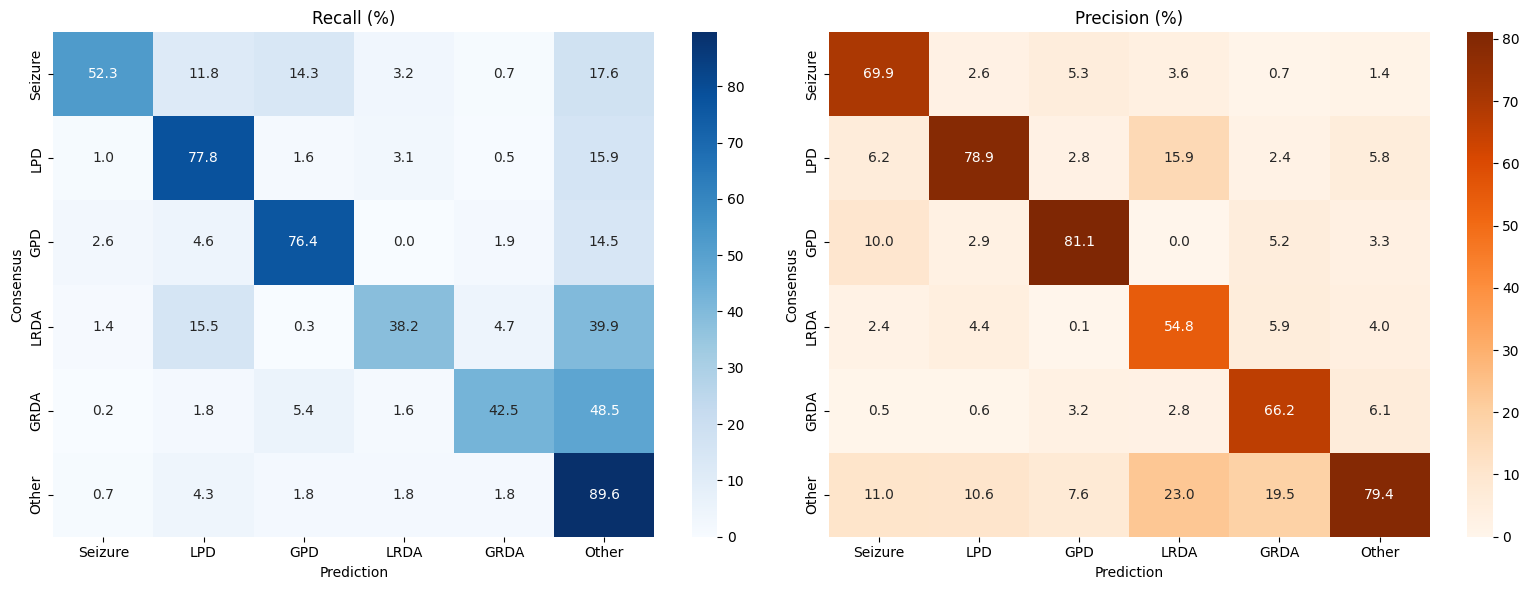

   Class |  AUROC| Paper |  Recall|  Paper |    Prec|  Paper
------------------------------------------------------------------------
 Seizure | 0.973|0.972 |   52.3%|  57.7% |   69.9%|  68.2%
     LPD | 0.963|0.962 |   77.8%|  80.3% |   78.9%|  77.5%
     GPD | 0.976|0.972 |   76.4%|  73.8% |   81.1%|  80.4%
    LRDA | 0.939|0.938 |   38.2%|  36.8% |   54.8%|  55.6%
    GRDA | 0.951|0.949 |   42.5%|  40.7% |   66.2%|  63.0%
   Other | 0.928|0.930 |   89.6%|  88.2% |   79.4%|  79.6%


In [16]:
# Per-class metrics vs paper (Figure 3, ≥10-label subset)
import seaborn as sns
yti = all_yt.argmax(1); ypi = all_yp.argmax(1)
ytb = (yti[:, None] == np.arange(6)).astype(int)
cm = confusion_matrix(yti, ypi, labels=range(6))
with np.errstate(invalid='ignore', divide='ignore'):
    cm_r = cm.astype('float') / cm.sum(1, keepdims=True) * 100
    cm_p = cm.astype('float') / cm.sum(0, keepdims=True) * 100

fig, (a1, a2) = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(cm_r, annot=True, fmt='.1f', cmap='Blues', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=a1)
a1.set_title('Recall (%)'); a1.set_xlabel('Prediction'); a1.set_ylabel('Consensus')
sns.heatmap(cm_p, annot=True, fmt='.1f', cmap='Oranges', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, ax=a2)
a2.set_title('Precision (%)'); a2.set_xlabel('Prediction'); a2.set_ylabel('Consensus')
plt.tight_layout(); plt.savefig(os.path.join(OUTPUT_DIR, 'confusion.png'), dpi=150); plt.show()

par = [0.972, 0.962, 0.972, 0.938, 0.949, 0.930]
prc = [57.7, 80.3, 73.8, 36.8, 40.7, 88.2]
ppr = [68.2, 77.5, 80.4, 55.6, 63.0, 79.6]
print(f'{"Class":>8} | {"AUROC":>6}|{"Paper":>6} | {"Recall":>7}|{"Paper":>7} | {"Prec":>7}|{"Paper":>7}')
print('-' * 72)
for i, nm in enumerate(CLASS_NAMES):
    try:
        auc = roc_auc_score(ytb[:, i], all_yp[:, i])
    except ValueError:
        auc = float('nan')   # class absent (smoke test)
    print(f'{nm:>8} | {auc:.3f}|{par[i]:.3f} | {cm_r[i,i]:6.1f}%|{prc[i]:6.1f}% | {cm_p[i,i]:6.1f}%|{ppr[i]:6.1f}%')

## Package stage-2 weights for the Kaggle inference notebook

In [17]:
import shutil
pkg = f'{PROJECT_DIR}/kaggle_upload/vipeegnet-weights' + RUN_SUFFIX
os.makedirs(pkg, exist_ok=True)
for i in FOLDS_TO_RUN:
    src = os.path.join(OUTPUT_DIR, f'fold{i}_stage2.weights.h5')
    if os.path.exists(src):
        shutil.copy2(src, pkg)
print(f'Copied to {pkg}:')
for f in sorted(os.listdir(pkg)):
    print(f'  {f} ({os.path.getsize(os.path.join(pkg, f))/1e6:.1f} MB)')
print('Next: kaggle datasets init -p', pkg, ' (edit title/id) then  kaggle datasets create -p', pkg)

Copied to /home/nfs/jhb-dehzangi/ws04/gs1147/hms/kaggle_upload/vipeegnet-weights_seed2026:
  fold0_stage2.weights.h5 (155.8 MB)
  fold1_stage2.weights.h5 (155.8 MB)
  fold2_stage2.weights.h5 (155.8 MB)
  fold3_stage2.weights.h5 (155.8 MB)
  fold4_stage2.weights.h5 (155.8 MB)
Next: kaggle datasets init -p /home/nfs/jhb-dehzangi/ws04/gs1147/hms/kaggle_upload/vipeegnet-weights_seed2026  (edit title/id) then  kaggle datasets create -p /home/nfs/jhb-dehzangi/ws04/gs1147/hms/kaggle_upload/vipeegnet-weights_seed2026
